# 🤖 AI & ML — Task 2: Feature Engineering, Model Optimization & Performance Comparison
**Dataset:** California Housing &nbsp;|&nbsp; **Goal:** prepare data correctly, train several regression models, compare them with objective metrics and justify the final choice.

| Task step | Notebook section |
|---|---|
| Step 1 Import libraries | 1 |
| Step 2 Load the dataset | 2 |
| Quick data check (why scaling matters) | 3 |
| Step 3 Separate features and target | 4 |
| Step 5 Train–test split, then Step 4 Feature scaling | 5 |
| Step 6 Train multiple models (+ optimisation) | 6 |
| Step 7 Evaluation and comparison table | 7 |
| Step 8 Visual validation (+ extra charts) | 8 |
| Final model selection, justification, joblib | 9 |
| Export results and the 1–2 page PDF | 10 |

> **Two deliberate improvements over the task's sample code**
> 1. **Split first, then scale.** The sample scales *all* data before splitting, which lets test-set statistics leak into training (data leakage). Here the `StandardScaler` lives in a `Pipeline` and is fitted on the training set only.
> 2. **No `squared=False`.** That argument was removed from `mean_squared_error` in recent scikit-learn; we use `np.sqrt(mean_squared_error(...))`, which works in every version.
>
> **Run:** `Kernel → Restart & Run All` (first run needs internet once to download the data; ~1–2 minutes).

## 1. Import libraries (Step 1)

In [1]:
import json, time, warnings
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib, sklearn

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, KFold
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

from housing_utils import FEATURES, add_features      # add_features = our feature-engineering step

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

SEED, TARGET = 42, "HousePrice"
ROOT = Path.cwd()
FIG_DIR, MODEL_DIR, DATA_DIR = ROOT / "figures", ROOT / "models", ROOT / "data"
for d in (FIG_DIR, MODEL_DIR, DATA_DIR): d.mkdir(exist_ok=True)

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

def score(y_true, y_pred):
    """MAE, RMSE (primary metric) and R2 as floats."""
    return {"mae": float(mean_absolute_error(y_true, y_pred)),
            "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "r2": float(r2_score(y_true, y_pred))}

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.9.1 | pandas 3.1.1


## 2. Load the dataset (Step 2)
Prices are in units of **$100,000** (so `2.5` = $250,000). A CSV copy is kept in `data/` so the notebook also works offline after the first run.

In [2]:
CSV_COPY = DATA_DIR / "california_housing.csv"

def load_data():
    try:
        data = fetch_california_housing(as_frame=True)
        df = pd.concat([data.data, data.target.rename(TARGET)], axis=1)
        df.to_csv(CSV_COPY, index=False)
        return df
    except Exception as err:
        if CSV_COPY.exists():
            print("Download failed, using local copy"); return pd.read_csv(CSV_COPY)
        raise RuntimeError("Could not download the dataset. Connect to the internet once (it is cached afterwards).") from err

df = load_data()
print("Shape:", df.shape)
df.head()

Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,HousePrice
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 3. Quick data check — why scaling matters

In [3]:
display(df.dtypes.to_frame("dtype").T)
print("Missing values:", int(df.isna().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()))
df.describe().T.round(2)

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,HousePrice
dtype,float64,float64,float64,float64,float64,float64,float64,float64,float64


Missing values: 0 | Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.87,1.90,0.50,2.56,3.53,4.74,15.00
HouseAge,20640.0,28.64,12.59,1.00,18.00,29.00,37.00,52.00
AveRooms,20640.0,5.43,2.47,0.85,4.44,5.23,6.05,141.91
AveBedrms,20640.0,1.10,0.47,0.33,1.01,1.05,1.10,34.07
Population,20640.0,1425.48,1132.46,3.00,787.00,1166.00,1725.00,35682.00
AveOccup,20640.0,3.07,10.39,0.69,2.43,2.82,3.28,1243.33
Latitude,20640.0,35.63,2.14,32.54,33.93,34.26,37.71,41.95
Longitude,20640.0,-119.57,2.00,-124.35,-121.80,-118.49,-118.01,-114.31
HousePrice,20640.0,2.07,1.15,0.15,1.20,1.80,2.65,5.00


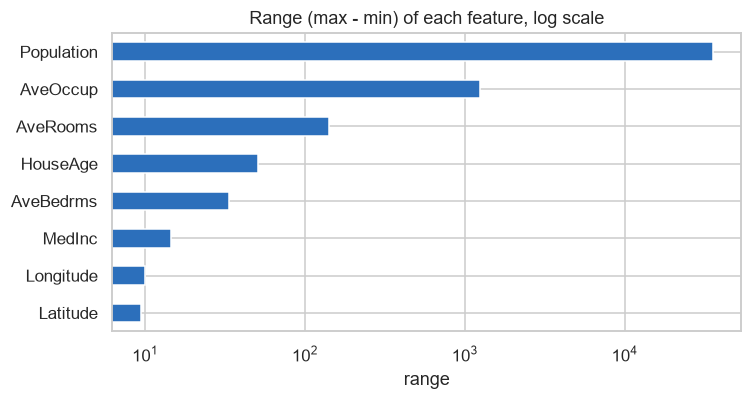

Largest range / smallest range = 3,792x


In [4]:
spread = (df[FEATURES].max() - df[FEATURES].min()).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.8))
spread.plot.barh(ax=ax, color="#2c6fbb"); ax.set_xscale("log")
ax.set(title="Range (max - min) of each feature, log scale", xlabel="range")
savefig("feature_scales")
print(f"Largest range / smallest range = {spread.max() / spread.min():,.0f}x")

The features live on **very different scales** (population ranges in the tens of thousands, latitude in single digits). Distance-based or regularised models such as **Ridge** treat large-scale features as more important unless the data is standardised, so scaling gives *fair learning across features*.

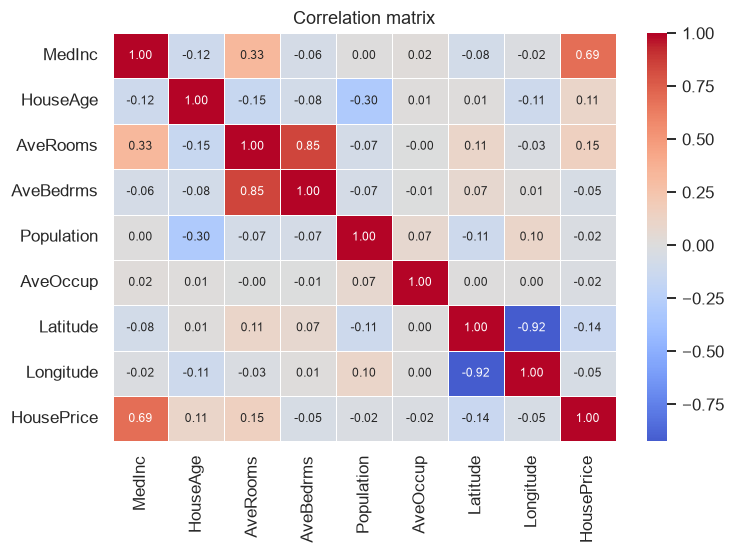

In [5]:
fig, ax = plt.subplots(figsize=(7, 5.2))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.4, annot_kws={"size": 8}, ax=ax)
ax.set_title("Correlation matrix"); savefig("correlation_heatmap")

## 4. Separate features and target (Step 3)

In [6]:
X = df.drop(TARGET, axis=1)
y = df[TARGET]
print("X:", X.shape, "| y:", y.shape)

X: (20640, 8) | y: (20640,)


## 5. Train–test split, then feature scaling (Steps 5 and 4)
**Order matters:** split first, then fit the scaler **only on the training data**. This keeps the test set truly unseen.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)

# Demonstration: what the scaler does (fitted on TRAIN only)
demo_scaler = StandardScaler().fit(X_train)
scaled = pd.DataFrame(demo_scaler.transform(X_train), columns=FEATURES)
display(pd.DataFrame({"mean before": X_train.mean(), "std before": X_train.std(),
                      "mean after": scaled.mean().values, "std after": scaled.std().values}).round(3))

Train: (16512, 8) | Test: (4128, 8)


,mean before,std before,mean after,std after
MedInc,3.881,1.904,-0.0,1.0
HouseAge,28.608,12.602,-0.0,1.0
AveRooms,5.435,2.387,0.0,1.0
AveBedrms,1.097,0.433,-0.0,1.0
Population,1426.453,1137.056,0.0,1.0
AveOccup,3.097,11.579,0.0,1.0
Latitude,35.643,2.137,0.0,1.0
Longitude,-119.582,2.006,0.0,1.0


After scaling every training feature has mean ≈ 0 and standard deviation ≈ 1. In the models below the scaler sits inside a `Pipeline`, so it is re-fitted automatically on each cross-validation training fold and applied (never re-fitted) to validation/test data.

## 6. Train multiple models (Step 6) and optimise them
**Stage A — the required models** (task Step 6):
* **Linear Regression** – baseline
* **Ridge Regression** (`alpha=1.0`) – L2 regularisation to reduce over-fitting
* **Decision Tree** (`max_depth=5`) – captures non-linear relationships

**Stage B — optimisation & extras:** `GridSearchCV` (5-fold, on the training set only) tunes Ridge's `alpha` and the tree's depth / leaf size; **feature engineering** (ratios, log transforms, distance to big cities) is added for the linear models; Random Forest and Gradient Boosting act as stronger non-linear references.

In [8]:
def make_pipe(model, engineer=False):
    steps = [("features", FunctionTransformer(add_features))] if engineer else []
    return Pipeline(steps + [("scaler", StandardScaler()), ("model", model)])

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
def grid(model, params, engineer=False):
    return GridSearchCV(make_pipe(model, engineer), params, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=-1)

# name -> (stage, family, estimator)
candidates = {
    "Linear Regression":                    ("A required", "linear",   make_pipe(LinearRegression())),
    "Ridge Regression (alpha=1.0)":         ("A required", "linear",   make_pipe(Ridge(alpha=1.0))),
    "Decision Tree (max_depth=5)":          ("A required", "tree",     make_pipe(DecisionTreeRegressor(max_depth=5, random_state=SEED))),
    "Ridge (tuned alpha)":                  ("B optimised", "linear",  grid(Ridge(), {"model__alpha": np.logspace(-3, 3, 13)})),
    "Decision Tree (tuned)":                ("B optimised", "tree",    grid(DecisionTreeRegressor(random_state=SEED), {"model__max_depth": [3, 5, 7, 9, 12], "model__min_samples_leaf": [1, 5, 20]})),
    "Linear Regression + features":         ("B optimised", "linear",  make_pipe(LinearRegression(), engineer=True)),
    "Ridge + features":                     ("B optimised", "linear",  grid(Ridge(), {"model__alpha": np.logspace(-3, 3, 13)}, engineer=True)),
    "Random Forest":                        ("B reference", "ensemble", make_pipe(RandomForestRegressor(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=SEED))),
    "Gradient Boosting (Hist)":             ("B reference", "ensemble", make_pipe(HistGradientBoostingRegressor(random_state=SEED))),
}

rows, fitted = [], {}
for name, (stage, family, est) in candidates.items():
    t0 = time.perf_counter()
    if isinstance(est, GridSearchCV):
        est.fit(X_train, y_train); cv_rmse, model = -est.best_score_, est.best_estimator_
        extra = ", ".join(f"{k.split('__')[1]}={v:.3g}" if isinstance(v, float) else f"{k.split('__')[1]}={v}" for k, v in est.best_params_.items())
    else:
        cv_rmse = -cross_val_score(est, X_train, y_train, cv=kf, scoring="neg_root_mean_squared_error").mean()
        model, extra = est.fit(X_train, y_train), ""
    fit_s = time.perf_counter() - t0
    tr, te = score(y_train, model.predict(X_train)), score(y_test, model.predict(X_test))
    rows.append(dict(name=name, stage=stage, family=family, best_params=extra, train_r2=tr["r2"], mae=te["mae"], rmse=te["rmse"], r2=te["r2"],
                     cv_rmse=float(cv_rmse), gap=tr["r2"] - te["r2"], fit_s=fit_s))
    fitted[name] = model
    print(f"{name:32s} test RMSE {te['rmse']:.3f}  R2 {te['r2']:.3f}  ({fit_s:.1f}s)  {extra}")

Linear Regression                test RMSE 0.746  R2 0.576  (0.3s)  
Ridge Regression (alpha=1.0)     test RMSE 0.746  R2 0.576  (0.2s)  
Decision Tree (max_depth=5)      test RMSE 0.724  R2 0.600  (0.9s)  
Ridge (tuned alpha)              test RMSE 0.746  R2 0.576  (7.7s)  alpha=3.16
Decision Tree (tuned)            test RMSE 0.601  R2 0.725  (5.1s)  max_depth=12, min_samples_leaf=20
Linear Regression + features     test RMSE 0.662  R2 0.666  (0.6s)  
Ridge + features                 test RMSE 0.662  R2 0.665  (3.1s)  alpha=31.6
Random Forest                    test RMSE 0.504  R2 0.806  (67.1s)  
Gradient Boosting (Hist)         test RMSE 0.465  R2 0.835  (11.7s)  


## 7. Evaluation and model performance comparison (Step 7)
* **RMSE** (lower is better) – typical size of the error, penalises big mistakes. *Primary metric.*
* **MAE** – average absolute error.
* **R²** (higher is better) – share of price variance explained.
* **CV RMSE** – 5-fold cross-validated RMSE on the **training** data; used to *select* the model so the test set is not used for choosing.
* **Overfit gap** = train R² − test R². A large gap means the model memorises the training data (introduction to over-fitting).

In [9]:
comp = pd.DataFrame(rows).set_index("name")
table = comp[["stage", "train_r2", "mae", "rmse", "r2", "cv_rmse", "gap", "fit_s", "best_params"]].rename(columns={
    "stage": "Stage", "train_r2": "Train R2", "mae": "Test MAE", "rmse": "Test RMSE", "r2": "Test R2",
    "cv_rmse": "CV RMSE", "gap": "Overfit gap", "fit_s": "Fit time (s)", "best_params": "Best params"})
table = table.sort_values("Test RMSE")
table.round(4).to_csv(ROOT / "model_comparison_table.csv")
display(table.round(4))

,Stage,Train R2,Test MAE,Test RMSE,Test R2,CV RMSE,Overfit gap,Fit time (s),Best params
name,,,,,,,,,
Gradient Boosting (Hist),B reference,0.8799,0.3111,0.4654,0.8347,0.4736,0.0452,11.6986,
Random Forest,B reference,0.9589,0.3260,0.5037,0.8064,0.5096,0.1525,67.0852,
Decision Tree (tuned),B optimised,0.8037,0.4060,0.6006,0.7247,0.6154,0.0790,5.1262,"max_depth=12, min_samples_leaf=20"
Linear Regression + features,B optimised,0.6862,0.4775,0.6620,0.6656,0.6620,0.0206,0.5678,
Ridge + features,B optimised,0.6855,0.4781,0.6621,0.6654,0.6611,0.0200,3.0720,alpha=31.6
Decision Tree (max_depth=5),A required,0.6377,0.5223,0.7242,0.5997,0.7227,0.0379,0.9406,
Ridge (tuned alpha),B optimised,0.6126,0.5332,0.7455,0.5759,0.7205,0.0367,7.7399,alpha=3.16
Ridge Regression (alpha=1.0),A required,0.6126,0.5332,0.7456,0.5758,0.7205,0.0367,0.1606,
Linear Regression,A required,0.6126,0.5332,0.7456,0.5758,0.7205,0.0368,0.2876,


The table is saved as `model_comparison_table.csv` (deliverable 2) and appears again in the PDF report.

## 8. Visual performance validation (Step 8 and extra charts)

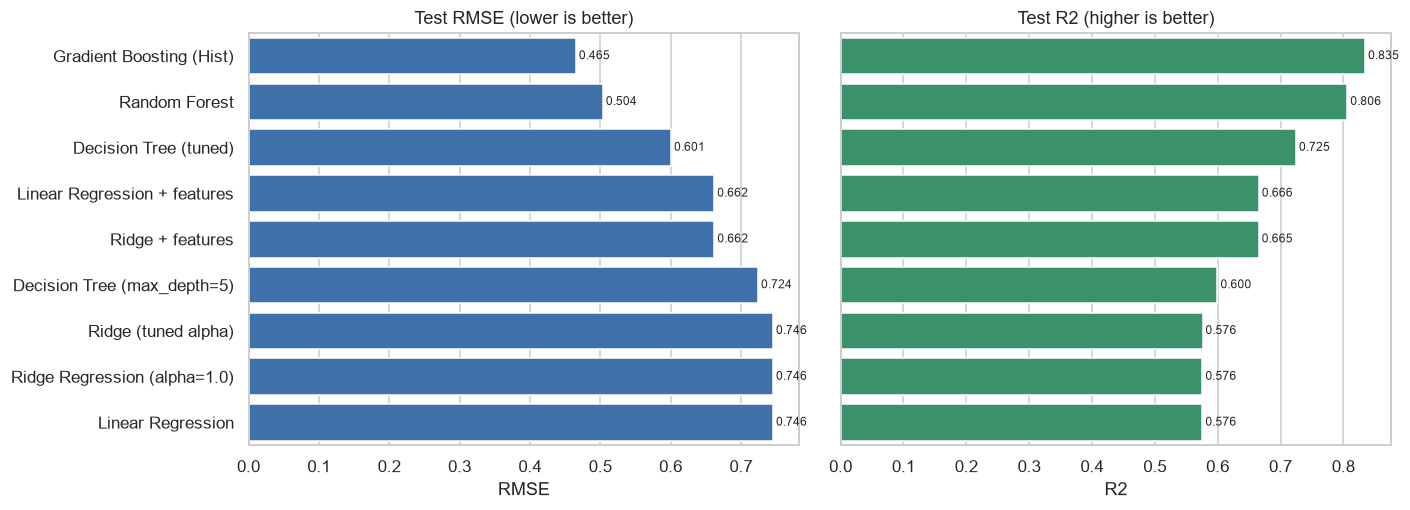

In [10]:
order = comp.sort_values("rmse").index
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.barplot(x=comp.loc[order, "rmse"], y=order, ax=axes[0], color="#2c6fbb"); axes[0].set(title="Test RMSE (lower is better)", ylabel="", xlabel="RMSE")
sns.barplot(x=comp.loc[order, "r2"], y=order, ax=axes[1], color="#2c9f6b"); axes[1].set(title="Test R2 (higher is better)", ylabel="", xlabel="R2")
for ax, col in zip(axes, ["rmse", "r2"]):
    for i, v in enumerate(comp.loc[order, col]): ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
axes[1].set_yticklabels([])
savefig("model_comparison")

### 8.1 Over-fitting check: train vs test R²

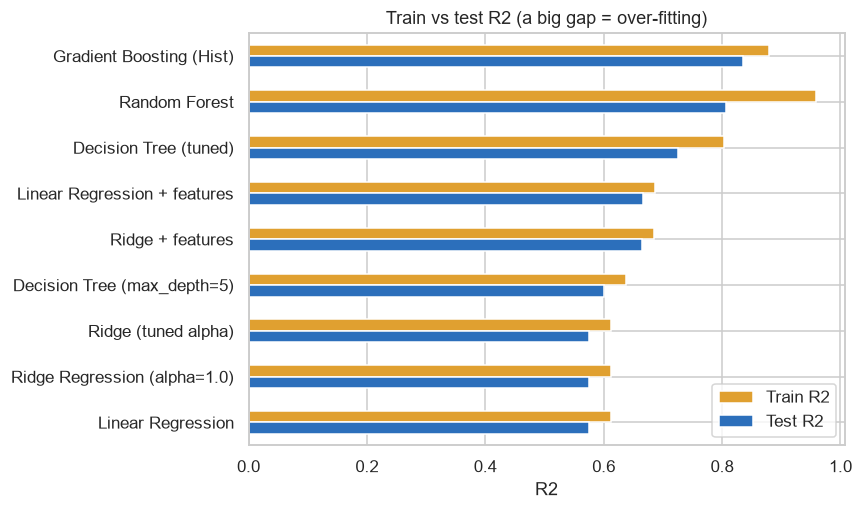

In [11]:
tt = comp.loc[order, ["train_r2", "r2"]].rename(columns={"train_r2": "Train R2", "r2": "Test R2"})
ax = tt.plot.barh(figsize=(8, 4.8), color=["#e0a030", "#2c6fbb"]); ax.invert_yaxis()
ax.set(title="Train vs test R2 (a big gap = over-fitting)", xlabel="R2", ylabel="")
savefig("train_vs_test_r2")

### 8.2 Final model selection (by cross-validated RMSE, not by the test set)

In [12]:
BASELINE, RIDGE_REQ, TREE_REQ = "Linear Regression", "Ridge Regression (alpha=1.0)", "Decision Tree (max_depth=5)"
best_overall = comp["cv_rmse"].idxmin()
best_linear = comp[comp["family"] == "linear"]["cv_rmse"].idxmin()
print("Selected model (lowest CV RMSE):", best_overall)
print("Best linear / interpretable model:", best_linear)

Selected model (lowest CV RMSE): Gradient Boosting (Hist)
Best linear / interpretable model: Ridge + features


### 8.3 Actual vs predicted (Step 8)

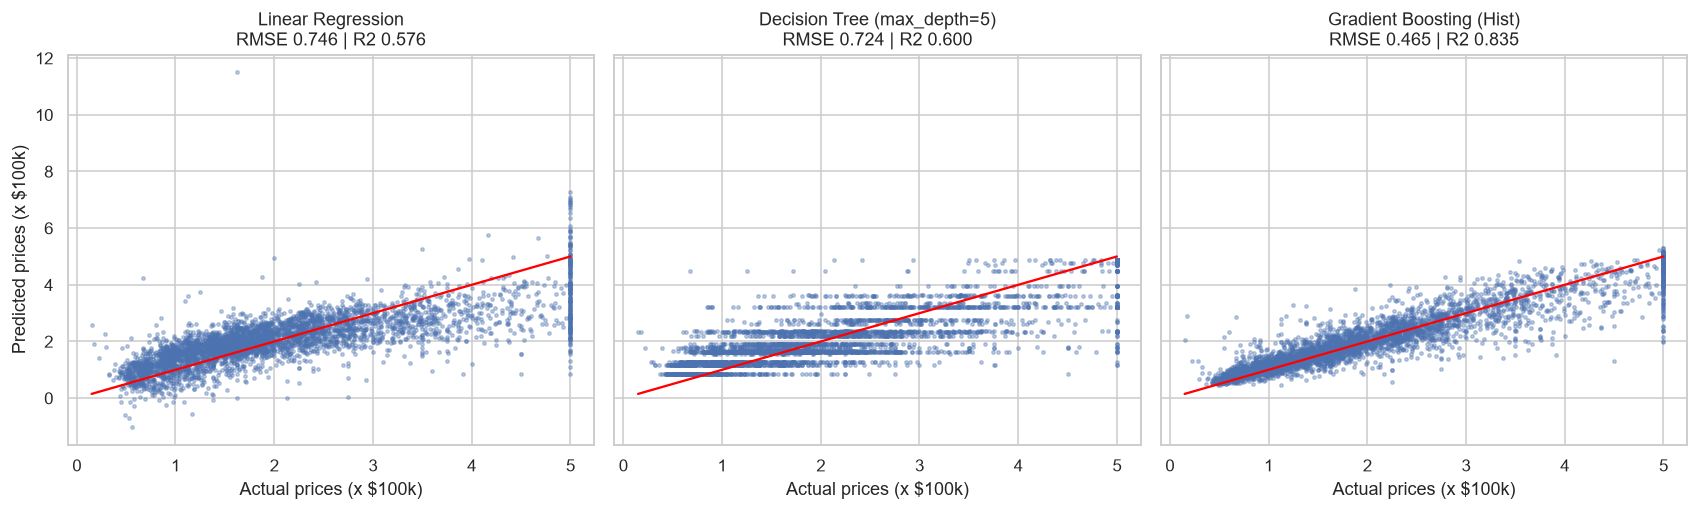

In [13]:
show = list(dict.fromkeys([BASELINE, TREE_REQ, best_overall]))
fig, axes = plt.subplots(1, len(show), figsize=(5.2 * len(show), 4.8), sharex=True, sharey=True)
axes = np.atleast_1d(axes)
for ax, name in zip(axes, show):
    pred = fitted[name].predict(X_test)
    ax.scatter(y_test, pred, s=5, alpha=.35)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
    ax.set(title=f"{name}\nRMSE {comp.loc[name, 'rmse']:.3f} | R2 {comp.loc[name, 'r2']:.3f}", xlabel="Actual prices (x $100k)")
axes[0].set_ylabel("Predicted prices (x $100k)")
savefig("actual_vs_predicted")

Points closer to the red diagonal mean better predictions. The straight-line model bends away for expensive houses, the shallow tree predicts in coarse steps, and the stronger models follow the diagonal more tightly. The horizontal band at the top comes from the dataset's $500,000 price cap.

### 8.4 What drives the selected model? (permutation importance)

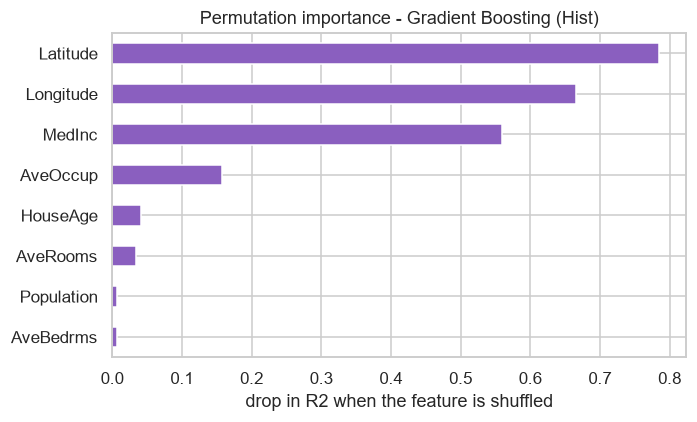

Latitude      0.785
Longitude     0.665
MedInc        0.560
AveOccup      0.157
HouseAge      0.042
AveRooms      0.034
Population    0.007
AveBedrms     0.006
dtype: float64

In [14]:
sample = X_test.sample(min(3000, len(X_test)), random_state=SEED)
imp = permutation_importance(fitted[best_overall], sample, y_test.loc[sample.index], n_repeats=5, random_state=SEED, n_jobs=-1)
imp_s = pd.Series(imp.importances_mean, index=FEATURES).sort_values()
ax = imp_s.plot.barh(figsize=(6.5, 4), color="#8a5fbf")
ax.set(title=f"Permutation importance - {best_overall}", xlabel="drop in R2 when the feature is shuffled")
savefig("feature_importance")
imp_s.sort_values(ascending=False).round(3)

## 9. Final model selection, justification and saving
**Why this model?** It is chosen with an objective, documented rule: the **lowest cross-validated RMSE on the training data**. The test set is only used afterwards to report honest performance. The code below prints the justification from your actual numbers, then saves the model with `joblib` (optional deliverable).

In [15]:
b, base = comp.loc[best_overall], comp.loc[BASELINE]
print(f"SELECTED MODEL : {best_overall}")
print(f"  CV RMSE {b.cv_rmse:.3f} | test RMSE {b.rmse:.3f} (about ${b.rmse * 100_000:,.0f}) | MAE {b.mae:.3f} | R2 {b.r2:.3f} | overfit gap {b.gap:+.3f}")
print(f"  vs baseline Linear Regression: RMSE {base.rmse:.3f} -> {b.rmse:.3f}  ({(b.rmse - base.rmse) / base.rmse * 100:+.1f}%),  R2 {base.r2:.3f} -> {b.r2:.3f}")
print(f"  Most interpretable alternative: {best_linear} (test RMSE {comp.loc[best_linear, 'rmse']:.3f}, R2 {comp.loc[best_linear, 'r2']:.3f})")
print(f"  Largest train-test gap: {comp['gap'].idxmax()} ({comp['gap'].max():+.3f})")

joblib.dump({"model": fitted[best_overall], "name": best_overall, "features": FEATURES,
             "metrics": {"mae": b.mae, "rmse": b.rmse, "r2": b.r2}, "target_unit": "USD 100,000",
             "trained_at": datetime.now(timezone.utc).strftime("%Y-%m-%d"), "sklearn_version": sklearn.__version__},
            MODEL_DIR / "best_model.pkl")

# reload test + prediction on a new house
loaded = joblib.load(MODEL_DIR / "best_model.pkl")
assert np.allclose(loaded["model"].predict(X_test), fitted[best_overall].predict(X_test))
house = pd.DataFrame([dict(MedInc=5.0, HouseAge=20, AveRooms=6.0, AveBedrms=1.0, Population=1500, AveOccup=3.0, Latitude=37.8, Longitude=-122.3)])
print(f"\nSaved models/best_model.pkl (reload test passed). Example prediction: ${loaded['model'].predict(house)[0] * 100_000:,.0f}")

SELECTED MODEL : Gradient Boosting (Hist)
  CV RMSE 0.474 | test RMSE 0.465 (about $46,540) | MAE 0.311 | R2 0.835 | overfit gap +0.045
  vs baseline Linear Regression: RMSE 0.746 -> 0.465  (-37.6%),  R2 0.576 -> 0.835
  Most interpretable alternative: Ridge + features (test RMSE 0.662, R2 0.665)
  Largest train-test gap: Random Forest (+0.153)

Saved models/best_model.pkl (reload test passed). Example prediction: $226,558


To reuse the saved model elsewhere: `bundle = joblib.load("models/best_model.pkl"); bundle["model"].predict(new_dataframe)` (keep `housing_utils.py` next to your script, because engineered-feature models import it).

## 10. Export results and build the 1–2 page PDF report

In [16]:
results = {
    "dataset": {"rows": int(len(df)), "features": FEATURES, "target": TARGET},
    "split": {"train": len(X_train), "test": len(X_test), "test_size": 0.2, "random_state": SEED},
    "comparison": [dict(name=n, **{k: (float(v) if not isinstance(v, str) else v) for k, v in r.items()}) for n, r in comp.iterrows()],
    "baseline": BASELINE, "ridge_required": RIDGE_REQ, "tree_required": TREE_REQ,
    "best_overall": best_overall, "best_linear": best_linear,
}
(ROOT / "results.json").write_text(json.dumps(results, indent=2))

import generate_report_task2
pdf = generate_report_task2.build_report(ROOT)
print("PDF report:", pdf)

PDF report: C:\Users\User\Downloads\Task2_Model_Comparison\Task2_Model_Comparison\AI_ML_Task2_Report.pdf


## 11. Conclusions
* Preparing the data correctly (split → scale inside a pipeline) and comparing several algorithms with the same metrics gives a **defensible, reproducible** model choice.
* **Feature engineering and non-linear models** improve results far more than tuning the linear model, whose limit is its straight-line assumption.
* The **overfit gap** shows that flexible models (deep trees, forests) fit the training data more tightly; cross-validation protects the selection from this.
* **Next steps:** wider hyper-parameter search, log-transformed target, handling the $500,000 price cap, spatial neighbour features, error analysis by region.

*Limitations: 1990 census block-group averages — a learning project, not a valuation tool.*